<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/reg-2-best-line.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What is the best line?

In [ ]:
# Setup: libraries, colors, plotting helpers, and the North Ames data
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Rectangle, FancyBboxPatch
import scipy.stats as stats
import statsmodels.formula.api as smf


PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
n = len(na)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
s = np.sqrt(np.sum(res ** 2) / (n - 2))
xbar, ybar = x.mean(), y.mean()
ssxx = np.sum((x - xbar) ** 2)
XS = np.linspace(700, 2400, 100)

# a fixed subset of 15 homes for the pictures with error segments
rng = np.random.default_rng(640)
sub = na.iloc[np.sort(rng.choice(n, 15, replace=False))]
xs_, ys_ = sub.area.values.astype(float), sub.price.values.astype(float)
a_s, b_s = fit(xs_, ys_)


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)
def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## Three candidate lines

Which of these lines is best? To compare lines we need to collapse all the vertical distances into one number. Each vertical segment is a **prediction error**, $y - \hat{y}$: the observed price minus the price the line predicts.

To keep the pictures readable, we use 15 of the 89 homes here. Everything works the same with all 89.

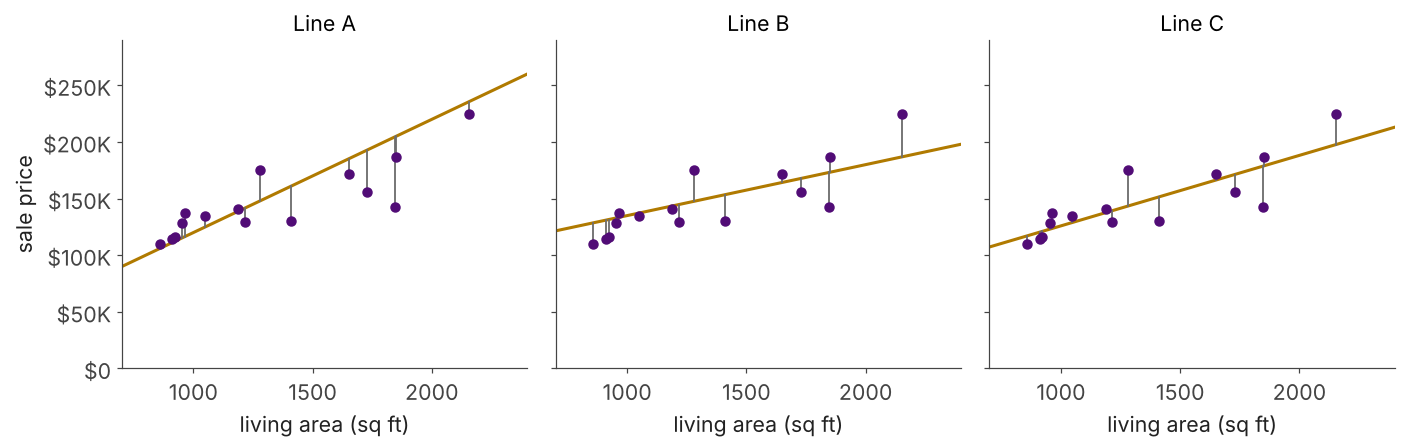

In [ ]:
# ---------------- 2. what does the best line mean ----------------
cands = [("Line A", 20000, 100.0), ("Line B", 90000, 45.0), ("Line C", a_s, b_s)]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, (nm, a, b) in zip(axs, cands):
    ax.plot(XS, a + b * XS, color=GOLD, lw=2)
    for xi, yi in zip(xs_, ys_):
        ax.plot([xi, xi], [yi, a + b * xi], color=GRAY, lw=1.2)
    ax.scatter(xs_, ys_, color=PURPLE, s=34, zorder=3)
    ax.set_title(nm); home_axes(ax)
    if ax is not axs[0]: ax.set_ylabel("")
fig.tight_layout(); plt.show()  # f07_three_lines.png

## Adding up the errors does not work

The first idea is to add the errors. Positive and negative errors cancel, and every line through the point of means $(\bar{x}, \bar{y})$ has errors that sum to zero, including the flat line on the left, which is obviously poor.

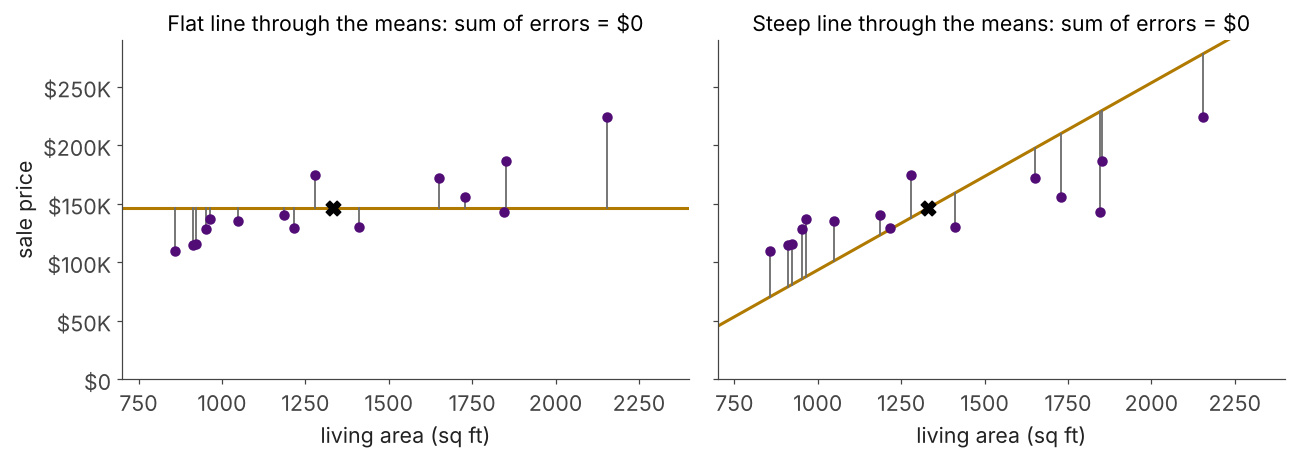

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
mx, my = xs_.mean(), ys_.mean()
for ax, (nm, b) in zip(axs, [("Flat line through the means", 0.0), ("Steep line through the means", 160.0)]):
    a = my - b * mx
    e = ys_ - (a + b * xs_)
    ax.plot(XS, a + b * XS, color=GOLD, lw=2)
    for xi, yi in zip(xs_, ys_):
        ax.plot([xi, xi], [yi, a + b * xi], color=GRAY, lw=1.2)
    ax.scatter(xs_, ys_, color=PURPLE, s=34, zorder=3)
    ax.scatter([mx], [my], marker="X", color="black", s=90, zorder=4)
    ax.set_title(f"{nm}: sum of errors = ${abs(e.sum()):,.0f}")
    home_axes(ax)
axs[1].set_ylabel("")
fig.tight_layout(); plt.show()  # f08_sum_zero.png

## Two ways to stop the cancelling

Take absolute values and average them, which gives the mean absolute error, or square the errors and add them up, which gives the sum of squared errors:

$$MAE = \frac{1}{n}\sum |y_i - \hat{y}_i| \qquad\qquad SSE = \sum (y_i - \hat{y}_i)^2$$

On the right, each square has the error as its side, so SSE is the total area of the squares. Dividing SSE by $n$ gives the mean squared error, which ranks lines the same way.

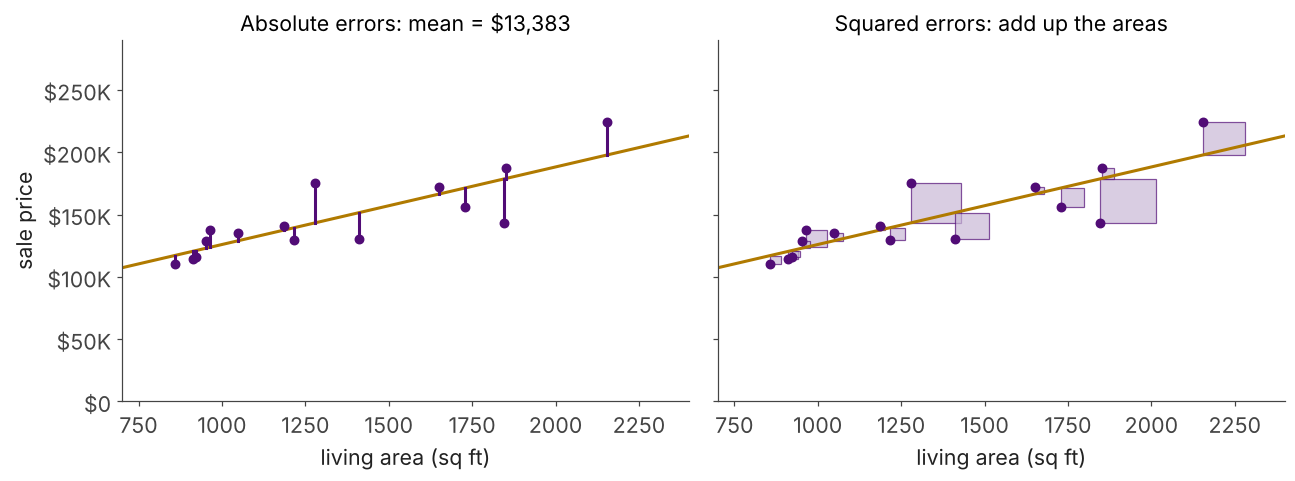

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
e = ys_ - (a_s + b_s * xs_)
yscale = (290000 - 0) / (2400 - 700) / 0.8   # make squares look square on this aspect
for ax, kind in zip(axs, ["abs", "sq"]):
    ax.plot(XS, a_s + b_s * XS, color=GOLD, lw=2)
    for xi, yi, ei in zip(xs_, ys_, e):
        if kind == "abs":
            ax.plot([xi, xi], [yi, yi - ei], color=PURPLE, lw=2)
        else:
            side = abs(ei)
            ax.add_patch(Rectangle((xi, min(yi, yi - ei)), side / yscale, side, fc=LIGHT, ec=PURPLE, lw=0.8, alpha=0.7))
    ax.scatter(xs_, ys_, color=PURPLE, s=30, zorder=3)
    home_axes(ax)
axs[0].set_title(f"Absolute errors: mean = ${np.mean(np.abs(e)):,.0f}")
axs[1].set_title("Squared errors: add up the areas")
axs[1].set_ylabel("")
fig.tight_layout(); plt.show()  # f09_abs_vs_sq.png

## Scoring the lines

Line D looks reasonable by eye and still loses. The **least squares line** is the line with the smallest SSE of all possible lines, not just of these four.

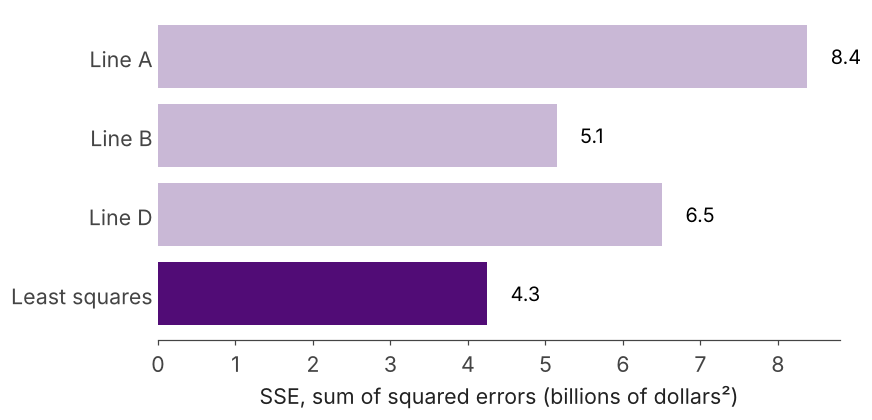

In [ ]:
# scoreboard
lines4 = [("Line A", 20000, 100.0), ("Line B", 90000, 45.0), ("Line D", 50000, 80.0), ("Least squares", a_s, b_s)]
rows = []
for nm, a, b in lines4:
    e = ys_ - (a + b * xs_)
    rows.append((nm, np.mean(np.abs(e)), np.sum(e ** 2), np.mean(e ** 2)))
fig, ax = plt.subplots(figsize=(8, 3.9))
names = [r[0] for r in rows]; sse = [r[2] / 1e9 for r in rows]
bars = ax.barh(names[::-1], sse[::-1], color=[PURPLE if nm == "Least squares" else LIGHT for nm in names[::-1]])
for bar, v in zip(bars, sse[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height() / 2, f"{v:,.1f}", va="center", fontsize=13)
ax.set_xlabel("SSE, sum of squared errors (billions of dollars²)")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
plt.show()  # f10_scoreboard.png

## Why squared errors are the usual choice

Squared errors are smooth, so calculus gives one exact answer, which mattered a great deal before computers. Squares also punish big misses much more than small ones: an error twice as large costs four times as much. And squares connect to variance and to the sums of squares we used in ANOVA, which is where the statistical theory comes from.

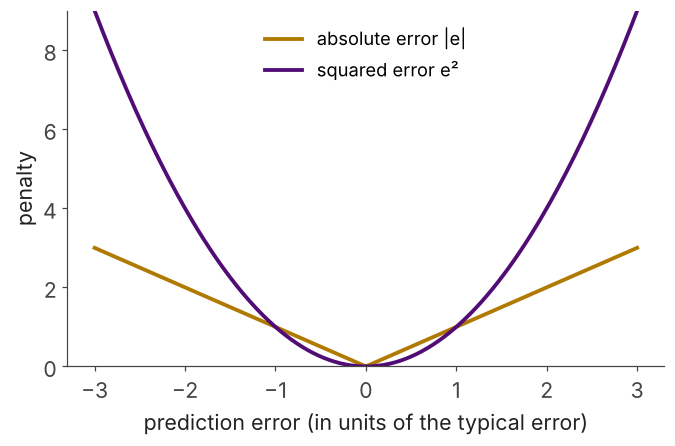

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ee = np.linspace(-3, 3, 200)
ax.plot(ee, np.abs(ee), color=GOLD, lw=2.5, label="absolute error |e|")
ax.plot(ee, ee ** 2, color=PURPLE, lw=2.5, label="squared error e²")
ax.set_xlabel("prediction error (in units of the typical error)"); ax.set_ylabel("penalty")
ax.set_ylim(0, 9); ax.legend(frameon=False, loc="upper center")
plt.show()  # f11_penalty.png

## When absolute errors are better

Squaring has a price: one unusual observation can pull the line. On the right, one hypothetical home has been added, a 1,150 sq ft home sold for \$265,000. The least squares line tilts toward it, and the least absolute errors line (also called median regression) barely moves.

We use least squares in this course, and we protect ourselves by looking at the data and the residuals.

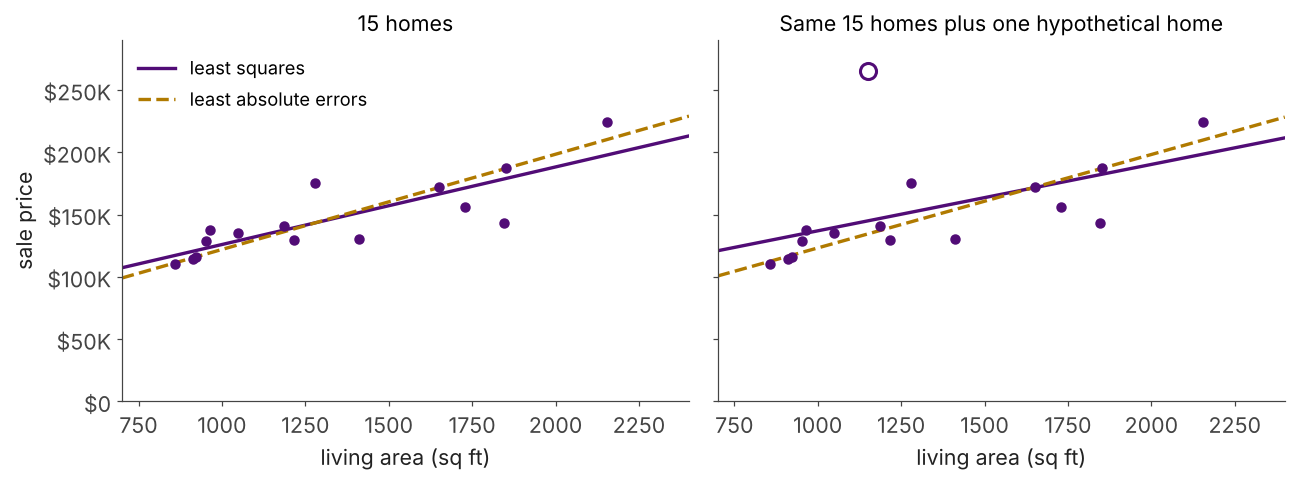

In [ ]:
# hypothetical unusual home: least squares vs least absolute deviations
xo = np.r_[xs_, 1150.0]; yo = np.r_[ys_, 265000.0]
def lad(xv, yv):
    m = smf.quantreg("y ~ x", pd.DataFrame({"x": xv, "y": yv})).fit(q=0.5)
    return m.params["Intercept"], m.params["x"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (xv, yv, ttl) in zip(axs, [(xs_, ys_, "15 homes"), (xo, yo, "Same 15 homes plus one hypothetical home")]):
    ax.scatter(xv, yv, color=PURPLE, s=34, zorder=3)
    if len(xv) > 15:
        ax.scatter([1150], [265000], facecolors="white", edgecolors=PURPLE, s=110, lw=2, zorder=4)
    a1, c1 = fit(xv, yv); a2, c2 = lad(xv, yv)
    ax.plot(XS, a1 + c1 * XS, color=PURPLE, lw=2.2, label="least squares")
    ax.plot(XS, a2 + c2 * XS, color=GOLD, lw=2.2, ls="--", label="least absolute errors")
    ax.set_title(ttl); home_axes(ax)
axs[0].legend(frameon=False, loc="upper left"); axs[1].set_ylabel("")
fig.tight_layout(); plt.show()  # f12_outlier.png

## The best line is the lowest point

Think of SSE as a valley over all combinations of intercept and slope, here for all 89 homes. Every point on this map is a line, and each contour connects lines with the same SSE. The least squares line sits at the bottom.

The long, tilted ovals show that intercept and slope trade off: a higher intercept with a lower slope fits almost as well.

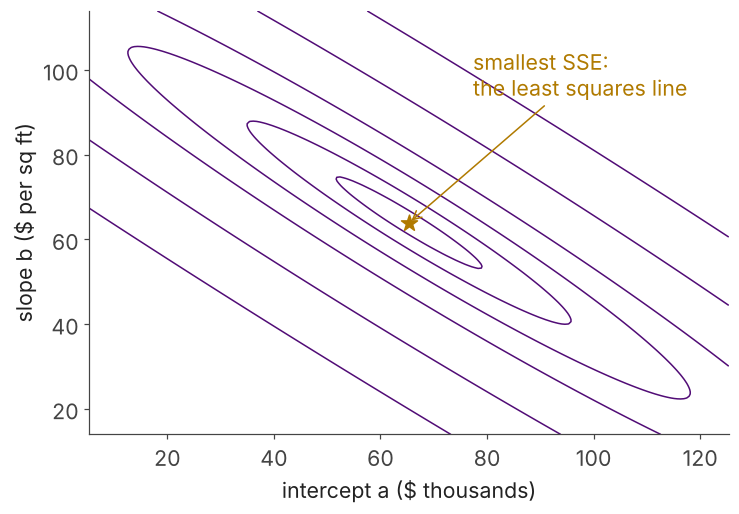

In [ ]:
# SSE over (a, b)
A = np.linspace(b0 - 60000, b0 + 60000, 200); B = np.linspace(b1 - 50, b1 + 50, 200)
AA, BB = np.meshgrid(A, B)
SSE = ((y[None, None, :] - AA[..., None] - BB[..., None] * x[None, None, :]) ** 2).sum(axis=2)
fig, ax = plt.subplots(figsize=(7.5, 5))
cs = ax.contour(AA / 1000, BB, SSE / 1e9, levels=np.quantile(SSE / 1e9, [0.01, 0.05, 0.15, 0.3, 0.5, 0.7]), colors=PURPLE, linewidths=1)
ax.scatter([b0 / 1000], [b1], color=GOLD, s=120, zorder=3, marker="*")
ax.annotate("smallest SSE:\nthe least squares line", xy=(b0 / 1000, b1), xytext=(b0 / 1000 + 12, b1 + 30), color=GOLD,
            arrowprops=dict(arrowstyle="->", color=GOLD))
ax.set_xlabel("intercept a ($ thousands)"); ax.set_ylabel("slope b ($ per sq ft)")
plt.show()  # f13_sse_contour.png